In [1]:
##################
### Keagan Moo ###
### 2023/08/15 ###
### GWAS Trait ###
##################

# This script loads in results files from AV's ldsc pipeline and work through a couple of plotting options to highlight significant results. 
suppressPackageStartupMessages({
library(tidyverse)
library(tidyr)
library(glue)
library(data.table)
library(ggplot2)
library(pheatmap)
library(hash)
    })

In [2]:
# Load in all the data

Types <- c("Type_1", "Type_2a", "Type_2x")
HARD_NUCTYPE_N <- 960 # Number of tests within each nuclei type
indir <- "/nfs/turbo/umms-scjp/kgmoo/analysis/20240424_kgmoo_SMldsc/results/annotation_enrichment/"
ldscRes <- list.files(indir, pattern = "*.results")
peakSets <- c()
traits <- c()
nucleiTypes <- c()
sexes <- c()
modelTypes <- c()
modelPatterns <- c()
pvalues <- c()
pvaluesBG <- c()
FDRs <- c()
FDR_BYs <- c()
coefs <- c()
coefsBG <- c()
heritabilities <- c()
heritabilitiesBG <- c()
for (fileTemp in ldscRes){
  print(fileTemp)
  label <- strsplit(gsub("\\.", ",", fileTemp), ",")
  print(label)
  if (length(label[[1]]) == 5){
    trait <- glue(label[[1]][1], label[[1]][2])
    peakSet <- label[[1]][4]
  } else if (length(label[[1]]) == 4){
    trait <- label[[1]][1]
    peakSet <- label[[1]][3]
  } else {
    print("fuck")
    break
  }
  meta <- strsplit(peakSet,"_")
  print(meta)
  if (length(meta[[1]]) == 6){
    nucleiTypes <- c(nucleiTypes, glue(meta[[1]][2], meta[[1]][3]))
    sexes <- c(sexes,meta[[1]][1])
    modelPatterns <- c(modelPatterns, meta[[1]][4])
  } else if (length(meta[[1]]) == 5) {
    nucleiTypes <- c(nucleiTypes, glue(meta[[1]][2], meta[[1]][3]))
    sexes <- c(sexes,meta[[1]][1])
    modelPatterns <- c(modelPatterns, "TOT")
  } else {
    print("fuck")
    break  
  }
  traits <- c(traits, trait)
  peakSets <- c(peakSets, peakSet)
  res <- read.table(glue(indir,fileTemp), header = TRUE)[1,]
  res2 <- read.table(glue(indir,fileTemp), header = TRUE)[2,]
  #print(res$Coefficient_z.score)
  #coefp1 <- pnorm(res$Coefficient_z.score, mean = 0, sd = 1, lower.tail = FALSE)
  heritability <- res$Prop._h2
  heritabilityBG <- res2$Prop._h2
  if(heritability < 0){
    message(glue("WARNING: {peakSet} and {trait} do not form a valid ldsc model, proportion of heritability is below zero, consider filtering out these results."))
  }
  heritabilities <- c(heritabilities, heritability)
  heritabilitiesBG <- c(heritabilitiesBG, heritabilityBG)
  coefp2 <- 2*pnorm(abs(res$Coefficient_z.score), mean = 0, sd = 1, lower.tail = FALSE)
  coefp2BG <- 2*pnorm(abs(res2$Coefficient_z.score), mean = 0, sd = 1, lower.tail = FALSE)
  FDRp2 <- p.adjust(coefp2, method = "bonferroni", n=HARD_NUCTYPE_N)
  FDR_BYp2 <- p.adjust(coefp2, method = "BY", n=HARD_NUCTYPE_N)
  pvalues <- c(pvalues, coefp2)
  pvaluesBG <- c(pvaluesBG, coefp2BG)
  FDRs <- c(FDRs, FDRp2)
  FDR_BYs <- c(FDR_BYs, FDR_BYp2)
  coefs <- c(coefs, res$Coefficient)
  coefsBG <- c(coefsBG, res2$Coefficient)
}

dfMelt <- data.frame(peakSet = peakSets, 
                     nucleiType = nucleiTypes, 
                     sex = sexes, 
                     modelPattern = modelPatterns, 
                     trait = traits, 
                     pValue = pvalues,
                     FDR_bon = FDRs,
                     FDR_BY = FDR_BYs,
                     coefValue = coefs,
                     h2 = heritabilities,
                     pValueBG = pvaluesBG,
                     coefValueBG = coefsBG,
                     h2BG = heritabilitiesBG)


[1] "102_irnt.annot.F_Type_1_DOWN_FDR1_bgo.results"
[[1]]
[1] "102_irnt"               "annot"                  "F_Type_1_DOWN_FDR1_bgo"
[4] "results"               

[[1]]
[1] "F"    "Type" "1"    "DOWN" "FDR1" "bgo" 

[1] "102_irnt.annot.F_Type_1_FDR1_bgo.results"
[[1]]
[1] "102_irnt"          "annot"             "F_Type_1_FDR1_bgo"
[4] "results"          

[[1]]
[1] "F"    "Type" "1"    "FDR1" "bgo" 

[1] "102_irnt.annot.F_Type_1_UP_FDR1_bgo.results"
[[1]]
[1] "102_irnt"             "annot"                "F_Type_1_UP_FDR1_bgo"
[4] "results"             

[[1]]
[1] "F"    "Type" "1"    "UP"   "FDR1" "bgo" 

[1] "102_irnt.annot.F_Type_2a_DOWN_FDR1_bgo.results"
[[1]]
[1] "102_irnt"                "annot"                  
[3] "F_Type_2a_DOWN_FDR1_bgo" "results"                

[[1]]
[1] "F"    "Type" "2a"   "DOWN" "FDR1" "bgo" 

[1] "102_irnt.annot.F_Type_2a_FDR1_bgo.results"
[[1]]
[1] "102_irnt"           "annot"              "F_Type_2a_FDR1_bgo"
[4] "results"           

[[1]]
[1] 

[1] "102_irnt.annot.M_Type_1_FDR1_bgo.results"
[[1]]
[1] "102_irnt"          "annot"             "M_Type_1_FDR1_bgo"
[4] "results"          

[[1]]
[1] "M"    "Type" "1"    "FDR1" "bgo" 



[1] "102_irnt.annot.M_Type_1_UP_FDR1_bgo.results"
[[1]]
[1] "102_irnt"             "annot"                "M_Type_1_UP_FDR1_bgo"
[4] "results"             

[[1]]
[1] "M"    "Type" "1"    "UP"   "FDR1" "bgo" 

[1] "102_irnt.annot.M_Type_2a_DOWN_FDR1_bgo.results"
[[1]]
[1] "102_irnt"                "annot"                  
[3] "M_Type_2a_DOWN_FDR1_bgo" "results"                

[[1]]
[1] "M"    "Type" "2a"   "DOWN" "FDR1" "bgo" 

[1] "102_irnt.annot.M_Type_2a_FDR1_bgo.results"
[[1]]
[1] "102_irnt"           "annot"              "M_Type_2a_FDR1_bgo"
[4] "results"           

[[1]]
[1] "M"    "Type" "2a"   "FDR1" "bgo" 

[1] "102_irnt.annot.M_Type_2a_UP_FDR1_bgo.results"
[[1]]
[1] "102_irnt"              "annot"                 "M_Type_2a_UP_FDR1_bgo"
[4] "results"              

[[1]]
[1] "M"    "Type" "2a"   "UP"   "FDR1" "bgo" 

[1] "102_irnt.annot.M_Type_2x_DOWN_FDR1_bgo.results"
[[1]]
[1] "102_irnt"                "annot"                  
[3] "M_Type_2x_DOWN_FDR1_bgo" "results"   

[1] "1050.annot.F_Type_1_FDR1_bgo.results"
[[1]]
[1] "1050"              "annot"             "F_Type_1_FDR1_bgo"
[4] "results"          

[[1]]
[1] "F"    "Type" "1"    "FDR1" "bgo" 

[1] "1050.annot.F_Type_1_UP_FDR1_bgo.results"
[[1]]
[1] "1050"                 "annot"                "F_Type_1_UP_FDR1_bgo"
[4] "results"             

[[1]]
[1] "F"    "Type" "1"    "UP"   "FDR1" "bgo" 

[1] "1050.annot.F_Type_2a_DOWN_FDR1_bgo.results"
[[1]]
[1] "1050"                    "annot"                  
[3] "F_Type_2a_DOWN_FDR1_bgo" "results"                

[[1]]
[1] "F"    "Type" "2a"   "DOWN" "FDR1" "bgo" 



[1] "1050.annot.F_Type_2a_FDR1_bgo.results"
[[1]]
[1] "1050"               "annot"              "F_Type_2a_FDR1_bgo"
[4] "results"           

[[1]]
[1] "F"    "Type" "2a"   "FDR1" "bgo" 



...

[1] "XVIII_MISCFINDINGS.annot.M_Type_1_FDR1_bgo.results"
[[1]]
[1] "XVIII_MISCFINDINGS" "annot"              "M_Type_1_FDR1_bgo" 
[4] "results"           

[[1]]
[1] "M"    "Type" "1"    "FDR1" "bgo" 



[1] "XVIII_MISCFINDINGS.annot.M_Type_1_UP_FDR1_bgo.results"
[[1]]
[1] "XVIII_MISCFINDINGS"   "annot"                "M_Type_1_UP_FDR1_bgo"
[4] "results"             

[[1]]
[1] "M"    "Type" "1"    "UP"   "FDR1" "bgo" 



[1] "XVIII_MISCFINDINGS.annot.M_Type_2a_DOWN_FDR1_bgo.results"
[[1]]
[1] "XVIII_MISCFINDINGS"      "annot"                  
[3] "M_Type_2a_DOWN_FDR1_bgo" "results"                

[[1]]
[1] "M"    "Type" "2a"   "DOWN" "FDR1" "bgo" 

[1] "XVIII_MISCFINDINGS.annot.M_Type_2a_FDR1_bgo.results"
[[1]]
[1] "XVIII_MISCFINDINGS" "annot"              "M_Type_2a_FDR1_bgo"
[4] "results"           

[[1]]
[1] "M"    "Type" "2a"   "FDR1" "bgo" 



[1] "XVIII_MISCFINDINGS.annot.M_Type_2a_UP_FDR1_bgo.results"
[[1]]
[1] "XVIII_MISCFINDINGS"    "annot"                 "M_Type_2a_UP_FDR1_bgo"
[4] "results"              

[[1]]
[1] "M"    "Type" "2a"   "UP"   "FDR1" "bgo" 



[1] "XVIII_MISCFINDINGS.annot.M_Type_2x_DOWN_FDR1_bgo.results"
[[1]]
[1] "XVIII_MISCFINDINGS"      "annot"                  
[3] "M_Type_2x_DOWN_FDR1_bgo" "results"                

[[1]]
[1] "M"    "Type" "2x"   "DOWN" "FDR1" "bgo" 

[1] "XVIII_MISCFINDINGS.annot.M_Type_2x_FDR1_bgo.results"
[[1]]
[1] "XVIII_MISCFINDINGS" "annot"              "M_Type_2x_FDR1_bgo"
[4] "results"           

[[1]]
[1] "M"    "Type" "2x"   "FDR1" "bgo" 

[1] "XVIII_MISCFINDINGS.annot.M_Type_2x_UP_FDR1_bgo.results"
[[1]]
[1] "XVIII_MISCFINDINGS"    "annot"                 "M_Type_2x_UP_FDR1_bgo"
[4] "results"              

[[1]]
[1] "M"    "Type" "2x"   "UP"   "FDR1" "bgo" 



,peakSet,nucleiType,sex,modelPattern,trait,pValue,FDR_bon,FDR_BY,coefValue,h2,pValueBG,coefValueBG,h2BG
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2267,M_Type_2x_FDR1_bgo,Type2x,M,TOT,2080,0.004758000,1.0000000,1,1.078969e-06,0.009999902,0.89302480,2.966331e-09,0.03022694
2268,M_Type_2x_UP_FDR1_bgo,Type2x,M,UP,2080,0.001417487,1.0000000,1,1.622127e-06,0.005546971,0.86733743,3.697748e-09,0.03076047
2493,F_Type_2x_UP_FDR1_bgo,Type2x,F,UP,2247_0,0.001505094,1.0000000,1,2.234024e-06,0.002853731,0.02485582,4.206449e-08,0.12859918
2511,F_Type_2x_UP_FDR1_bgo,Type2x,F,UP,2247_1,0.001301582,1.0000000,1,2.314124e-06,0.002937476,0.02624573,4.158063e-08,0.12859022
3364,M_Type_2x_DOWN_FDR1_bgo,Type2x,M,DOWN,2754_irnt,0.001286395,1.0000000,1,3.678797e-06,0.007196893,0.93354080,4.473320e-09,0.03210175
3365,M_Type_2x_FDR1_bgo,Type2x,M,TOT,2754_irnt,0.000262851,0.2523369,1,3.115135e-06,0.009689313,0.92556013,5.015311e-09,0.03229478
3382,M_Type_2x_DOWN_FDR1_bgo,Type2x,M,DOWN,2764_irnt,0.005847575,1.0000000,1,4.151190e-06,0.013757696,0.91908249,-4.263686e-09,0.06883215
3383,M_Type_2x_FDR1_bgo,Type2x,M,TOT,2764_irnt,0.002653069,1.0000000,1,3.215298e-06,0.016846328,0.93450941,-3.450175e-09,0.06923480
3886,M_Type_2x_DOWN_FDR1_bgo,Type2x,M,DOWN,399_irnt,0.002369751,1.0000000,1,1.320951e-06,0.008818998,0.01771957,4.030568e-08,0.05561058


,peakSet,nucleiType,sex,modelPattern,trait,pValue,FDR_bon,FDR_BY,coefValue,h2,pValueBG,coefValueBG,h2BG
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
7003,F_Type_1_DOWN_FDR1_bgo,Type1,F,DOWN,MAGIC2023_ISIadjbmi,0.681176568,1,1,1.031720e-06,4.184897e-03,0.6102069,4.153489e-08,0.08208155
7004,F_Type_1_FDR1_bgo,Type1,F,TOT,MAGIC2023_ISIadjbmi,0.083413975,1,1,3.979725e-06,2.100676e-02,0.6114737,4.131392e-08,0.08158496
7005,F_Type_1_UP_FDR1_bgo,Type1,F,UP,MAGIC2023_ISIadjbmi,0.008433755,1,1,1.053331e-05,1.894428e-02,0.6239132,3.995313e-08,0.07972445
7012,M_Type_1_DOWN_FDR1_bgo,Type1,M,DOWN,MAGIC2023_ISIadjbmi,0.688343104,1,1,2.304447e-06,1.167785e-03,0.6090058,4.166094e-08,0.08217160
7013,M_Type_1_FDR1_bgo,Type1,M,TOT,MAGIC2023_ISIadjbmi,0.952089922,1,1,-2.459268e-07,7.790029e-06,0.6114476,4.138314e-08,0.08194060
7014,M_Type_1_UP_FDR1_bgo,Type1,M,UP,MAGIC2023_ISIadjbmi,0.439329572,1,1,-4.459155e-06,-1.002358e-03,0.6129149,4.123053e-08,0.08201302


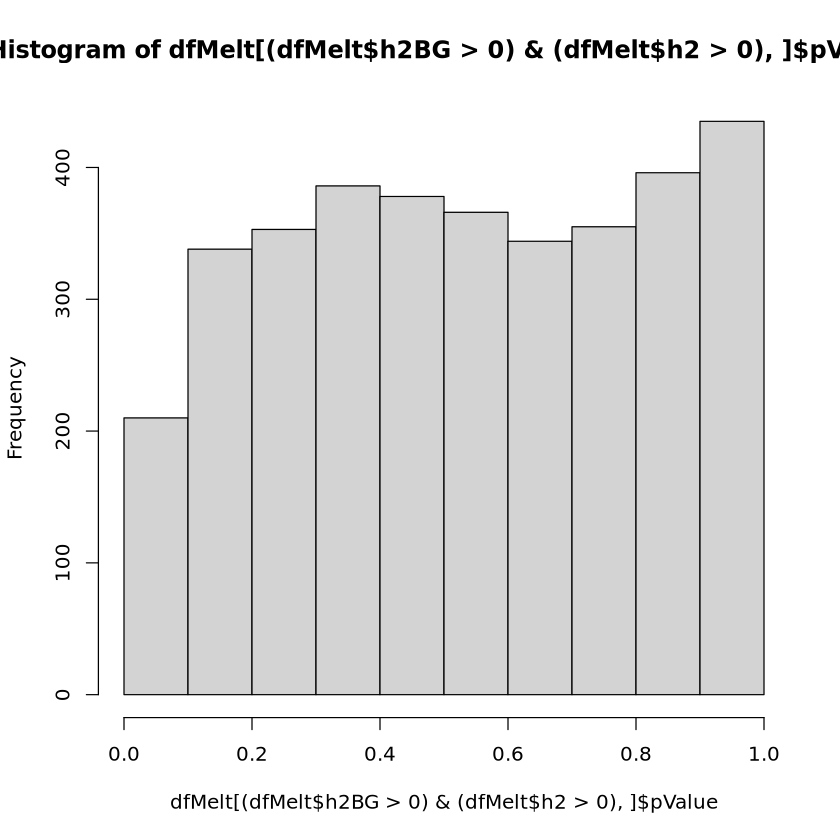

In [7]:
(dfMelt[(dfMelt$pValue < 0.01) & (dfMelt$h2BG > 0) & (dfMelt$h2 > 0),])
hist(dfMelt[(dfMelt$h2BG > 0) & (dfMelt$h2 > 0),]$pValue)
(dfMelt[(dfMelt$trait == "MAGIC2023_ISIadjbmi") & (dfMelt$nucleiType == "Type1"),])